<a href="https://colab.research.google.com/github/zcflanzer/rcew-water-budget/blob/main/bivariate_plot.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# OpenET data
Author: Zoe Flanzer\
Last updated: 11/5/2026\
Purpose: To create a bivariate map of tree cover and ET change. The map displays significant areas with either tree or ET increase/decrease (or no change).

In [1]:
## setting up notebook
# importing important libraries
import ee
import geemap
import matplotlib.pyplot as plt
import geopandas as gpd
import os
import numpy as np
import rasterio
from matplotlib.colors import ListedColormap
from scipy.stats import norm
from google.colab import files
from rasterio.features import geometry_mask
from shapely import force_2d

# authenticate & initialize Earth Engine
ee.Authenticate()
ee.Initialize(project = 'ee-zoeflanzer') # change project name

# mount Google Drive
from google.colab import drive
drive.mount('/content/drive', force_remount=False)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
## importing shapefile
# full tollgate shapefile
shp = gpd.read_file('/content/drive/MyDrive/THESIS/data/Shapefiles/tollgate_edited.shp') # importing shape file
if shp.crs is None: # setting crs
   shp.crs = 'EPSG:26911'
shp = shp.to_crs('EPSG:4326') # reprojecting to correspond to OpenET
fc = geemap.geopandas_to_ee(shp) # converting shapefile to GEE feature
aoi = fc.geometry()

# elevation quartile paths
quart_dir = '/content/drive/MyDrive/THESIS/data/Other/hypsometric_quartiles_APPROX'
quartile_files = {f'Q{i}': f'{quart_dir}/contour_quartile_{i}.shp' for i in range(1, 5)}

# stream channel shapefile
shp_stream = gpd.read_file('/content/drive/MyDrive/THESIS/data/Shapefiles/stream_channels/Stream Channels.shp')
shp_stream = shp_stream.to_crs('EPSG:4326')
shp_stream = shp_stream.explode(index_parts=False).reset_index(drop=True) # splitting multi-part lines into single lines
shp_stream['geometry'] = shp_stream.geometry.apply(force_2d) # get rid of z values
shp_stream = shp_stream[['geometry']] # keep geometry
fc_stream = geemap.geopandas_to_ee(shp_stream)

/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:200: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D LineString' is converted to 'LineString Z'
  return ogr_read(


In [3]:
# defining early and late 3-year windows to smooth annual noise around 2000 and 2020
early_start, early_end = '2000-01-01', '2003-01-01'
late_start, late_end   = '2019-01-01', '2022-01-01'

In [4]:
## tree change data
veg_data = ee.ImageCollection("USGS/NLCD_RELEASES/2023_REL/RCMAP/V6/COVER") \
    .filterBounds(fc) \
    .select('rangeland_tree')

tree_early = veg_data.filterDate(early_start, early_end).mean()
tree_late  = veg_data.filterDate(late_start, late_end).mean()
tree_change = tree_late.subtract(tree_early).rename('tree_change')

In [5]:
## ET data
et_data = ee.ImageCollection("OpenET/ENSEMBLE/CONUS/GRIDMET/MONTHLY/v2_0") \
    .filterBounds(fc) \
    .select('et_ensemble_mad')

def annual_et(year):
    year = ee.Number(year)
    start = ee.Date.fromYMD(year, 1, 1)
    end = start.advance(1, 'year')
    return et_data.filterDate(start, end).sum().set('year', year)

early_years = ee.List.sequence(2000, 2002)
late_years  = ee.List.sequence(2019, 2021)

et_early = ee.ImageCollection(early_years.map(annual_et)).mean()
et_late  = ee.ImageCollection(late_years.map(annual_et)).mean()
et_change = et_late.subtract(et_early).rename('et_change')

/usr/local/lib/python3.13/dist-packages/ee/deprecation.py:215: DeprecationWarning: 

Attention required for OpenET/ENSEMBLE/CONUS/GRIDMET/MONTHLY/v2_0! You are using a deprecated asset.
To make sure your code keeps working, please update it.
This dataset has been superseded by projects/openet/assets/ensemble/conus/gridmet/monthly/v2_0

Learn more: https://developers.google.com/earth-engine/datasets/catalog/OpenET_ENSEMBLE_CONUS_GRIDMET_MONTHLY_v2_0

  warnings.warn(warning, category=DeprecationWarning)


In [6]:
## parameters
start_year, end_year = 2000, 2021
alpha    = 0.05
et_tol   = 5                       # mm/yr; |ET change| <= et_tol counts as "no change" - 10
veg_tol  = 1                        # percentage points; |veg change| <= veg_tol counts as "no change" - 2
veg_band   = 'rangeland_tree'
veg_change = tree_change
veg_label  = 'Tree cover change'

Significant ET trend: 46,914 px | Tree cover change: 29,874 px | both: 20,220 | either: 56,568
Pixels per bivariate class: {'0': 61, '1': 108, '2': 15, '3': 148, '4': 27362.04705882351, '5': 8990.29411764706, '6': 23.184313725490195, '7': 27587.52549019609, '8': 19110.35294117646}
Generating URL ...
Please wait ...


Data downloaded to /content/svg_exports/bivariate_sig_with_white.tif
Class counts: {0: 61, 1: 108, 2: 15, 3: 148, 4: 27673, 5: 9023, 6: 24, 7: 27963, 8: 19207, 255: 61968}


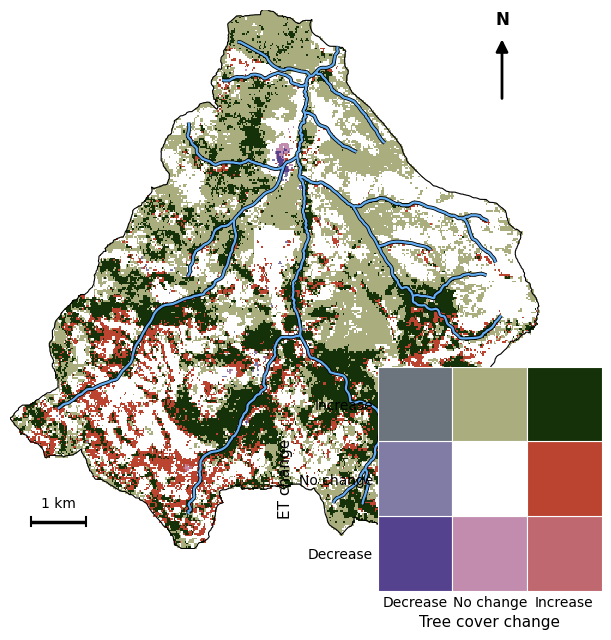

In [7]:
## plotting Tollgate bivariate map
# colors
palette = ['54428E', 'C28CAE', 'BF686F',   # ET decrease: veg decrease -> no change -> increase
           '817CA6', 'FFFFFF', 'BB4430',   # ET no change
           '6C757D', 'AAAE7F', '143109']   # ET increase

# parameters
out_dir        = 'svg_exports'
export_scale   = 30            # meters
NODATA         = 255
map_fig_size   = (7, 7)        # inches
boundary_color = 'black'
boundary_lw    = 0.8
show_streams   = True
stream_color      = '#63ADF2'
stream_lw         = 1.6
stream_outline    = '#000000'
stream_outline_lw = 0.6
legend_fontsize = 10
legend_axes     = [0.66, 0.05, 0.32, 0.32]
scalebar_km     = 1

# z value for mann-kendall
zcrit = norm.ppf(1 - alpha / 2)
year_list = list(range(start_year, end_year + 1))

# loading RCMAP images
veg_data_ts = (ee.ImageCollection("USGS/NLCD_RELEASES/2023_REL/RCMAP/V6/COVER").filterBounds(fc).select(veg_band))

# getting annual images
def annual_img(coll, y, reducer):
    sub = coll.filterDate(f'{y}-01-01', f'{y + 1}-01-01')
    img = sub.sum() if reducer == 'sum' else sub.mean()
    return img.toFloat().rename('v')

# one image per year for ET and tree cover
et_annual  = [annual_img(et_data, y, 'sum') for y in year_list]          # mm/yr
veg_annual = [annual_img(veg_data_ts, y, 'mean') for y in year_list]     # % cover

# mann kendall test
def mann_kendall(annual_imgs): # returns z-score and 0/1 significance image for masking
    n = len(annual_imgs)
    stack = ee.ImageCollection(annual_imgs).toBands() # staacking all years
    valid = stack.mask().reduce(ee.Reducer.min())
    bands = [stack.select([i]).unmask(0).rename('x') for i in range(n)] # splitting back up into years

    # direction of trend
    signs = [bands[j].subtract(bands[i]).signum().rename('x')
             for i in range(n - 1) for j in range(i + 1, n)]
    S = ee.ImageCollection(signs).sum()

    # tie correction
    tie_terms = []
    for i in range(n):
        c = ee.ImageCollection([bands[i].eq(bands[j]).rename('x')
                                for j in range(n) if j != i]).sum()
        tie_terms.append(c.multiply(c.multiply(2).add(7)).rename('x'))
    tie_sum = ee.ImageCollection(tie_terms).sum()

    # variance of S with tie correction
    var_S = ee.Image(n * (n - 1) * (2 * n + 5)).subtract(tie_sum).divide(18)
    z = S.subtract(S.signum()).divide(var_S.sqrt()) # corrected z-score
    sig = (z.abs().gt(zcrit).updateMask(valid).updateMask(var_S.gt(0)).rename('sig')) # mask pixels with missing years or zero variance
    return z.rename('z'), sig

# running trend test
et_z, et_sig   = mann_kendall(et_annual)
veg_z, veg_sig = mann_kendall(veg_annual)

# nnmask so "not significant" = 0 instead of masked
et_sig0  = et_sig.unmask(0)
veg_sig0 = veg_sig.unmask(0)

# signed classes with "no change" forced where not significant
def signed_class(img, tol, sig0, name):
    # 1 = decrease, 2 = no change, 3 = increase (non-significant pixels -> 2)
    cls = (ee.Image(2).where(img.lt(-tol), 1).where(img.gt(tol), 3))
    cls = cls.where(sig0.Not(), 2) # insignificant -> no change
    return cls.updateMask(img.mask()).rename(name)

# classifying magnitude of change
et_class_e  = signed_class(et_change, et_tol, et_sig0, 'et_class')
veg_class_e = signed_class(veg_change, veg_tol, veg_sig0, 'veg_class')

# pixels where at least tree cover or et significantly changed
either_sig = et_sig0.Or(veg_sig0)

# bivariate code -- combine classes to make 3x3 palette
bivar_sig = (et_class_e.subtract(1).multiply(3).add(veg_class_e.subtract(1)).rename('bivar_class'))

# summary stats
def count(img):
    r = img.reduceRegion(ee.Reducer.sum(), aoi, 30, maxPixels=1e9).getInfo()
    return int(list(r.values())[0] or 0)

# how many pixels have significant trends
n_et     = count(et_sig0.rename('c'))
n_veg    = count(veg_sig0.rename('c'))
n_both   = count(et_sig0.And(veg_sig0).rename('c'))
n_either = count(either_sig.rename('c'))
print(f'Significant ET trend: {n_et:,} px | {veg_label}: {n_veg:,} px | '
      f'both: {n_both:,} | either: {n_either:,}')

# pixel count per bivariate class
hist = bivar_sig.clip(fc).reduceRegion(ee.Reducer.frequencyHistogram(), aoi, 30, maxPixels=1e9).get('bivar_class').getInfo()
print('Pixels per bivariate class:',
      dict(sorted((hist or {}).items(), key=lambda kv: int(kv[0]))))

# legend
colors = ['#' + c for c in palette]
grid = [colors[r*3:(r+1)*3] for r in range(3)]
tick_labels = ['Decrease', 'No change', 'Increase']

def draw_legend(ax, fontsize=8, title=True):
    for row in range(3):
        for col in range(3):
            ax.add_patch(plt.Rectangle((col, row), 1, 1, facecolor=grid[row][col],
                                       edgecolor='white', lw=0.8))
    ax.set_xlim(0, 3); ax.set_ylim(0, 3); ax.set_aspect('equal')
    ax.set_xticks([0.5, 1.5, 2.5]); ax.set_xticklabels(tick_labels, fontsize=fontsize)
    ax.set_yticks([0.5, 1.5, 2.5]); ax.set_yticklabels(tick_labels, fontsize=fontsize)
    ax.set_xlabel(veg_label, fontsize=fontsize + 1)
    ax.set_ylabel('ET change', fontsize=fontsize + 1)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.tick_params(length=0)
    if title:
        ax.set_title(f'Bivariate legend\n(significant trends only, alpha = {alpha})',
                     fontsize=fontsize + 1)

# exporting svg of map and legend
os.makedirs(out_dir, exist_ok=True)
tif_path = os.path.join(out_dir, 'bivariate_sig_with_white.tif')

# export raster
export_img = bivar_sig.clip(fc).toByte().unmask(NODATA)
geemap.ee_export_image(export_img, filename=tif_path, scale=export_scale,region=aoi, crs='EPSG:4326', file_per_band=False)

with rasterio.open(tif_path, 'r+') as dst:
    dst.nodata = NODATA

with rasterio.open(tif_path) as src:
    arr = src.read(1)
    transform = src.transform
print('Class counts:', dict(zip(*[x.tolist() for x in np.unique(arr, return_counts=True)])))

# raster setup-- no vectorization to make editing easier
cmap = ListedColormap(colors)                       # palette
arr_masked = np.ma.masked_equal(arr, NODATA)        # NODATA stays transparent
left, top = transform.c, transform.f
right = left + transform.a * arr.shape[1]
bottom = top + transform.e * arr.shape[0]           # transform.e is negative

# map + legend svg
plt.rcParams['svg.fonttype'] = 'none'   # keep text as editable text, not outlines
fig, ax = plt.subplots(figsize=map_fig_size)

ax.imshow(arr_masked, cmap=cmap, vmin=0, vmax=8,extent=(left, right, bottom, top),interpolation='nearest', zorder=1)

shp.boundary.plot(ax=ax, color=boundary_color, linewidth=boundary_lw, zorder=2)

if show_streams:
    # black outline underneath, blue channel on top
    shp_stream.plot(ax=ax, color=stream_outline,linewidth=stream_lw + 2 * stream_outline_lw, zorder=3)
    shp_stream.plot(ax=ax, color=stream_color, linewidth=stream_lw, zorder=4)

# zoom to catchment boundary
minx, miny, maxx, maxy = shp.total_bounds
mid_lat = (miny + maxy) / 2
ax.set_xlim(minx, maxx); ax.set_ylim(miny, maxy)
ax.set_aspect(1 / np.cos(np.deg2rad(mid_lat)))   # correct lat/lon distortion
ax.set_axis_off()

# scale bar
km_per_deg_lon = 111.32 * np.cos(np.deg2rad(mid_lat))
bar_deg = scalebar_km / km_per_deg_lon
pad_x = (maxx - minx) * 0.04
pad_y = (maxy - miny) * 0.05
x0, y0 = minx + pad_x, miny + pad_y
tick_h = (maxy - miny) * 0.008
ax.plot([x0, x0 + bar_deg], [y0, y0], color='black', lw=2.5,solid_capstyle='butt', zorder=10)
for xt in (x0, x0 + bar_deg):
    ax.plot([xt, xt], [y0 - tick_h, y0 + tick_h], color='black', lw=1.5, zorder=10)
ax.text(x0 + bar_deg / 2, y0 + tick_h * 2.5, f'{scalebar_km} km',ha='center', va='bottom', fontsize=legend_fontsize, zorder=10)

# north arrow
ax.annotate('', xy=(0.93, 0.95), xytext=(0.93, 0.83), xycoords='axes fraction',arrowprops=dict(arrowstyle='-|>', color='black', lw=2, mutation_scale=18), zorder=10)
ax.text(0.93, 0.965, 'N', transform=ax.transAxes, ha='center', va='bottom',fontsize=legend_fontsize + 2, fontweight='bold', zorder=10)

# inset legend
lax = fig.add_axes(legend_axes)
draw_legend(lax, fontsize=legend_fontsize, title=False)

map_svg = os.path.join(out_dir, 'bivariate_map_sig_with_white.svg')
fig.savefig(map_svg, format='svg', bbox_inches='tight', transparent=False)
plt.show()

# download
#files.download(map_svg)

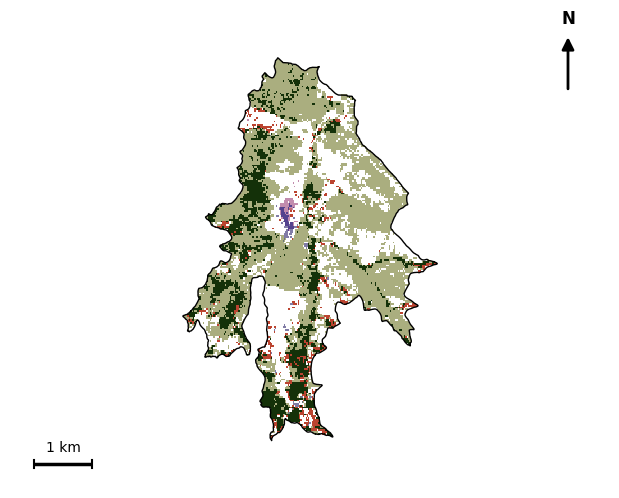

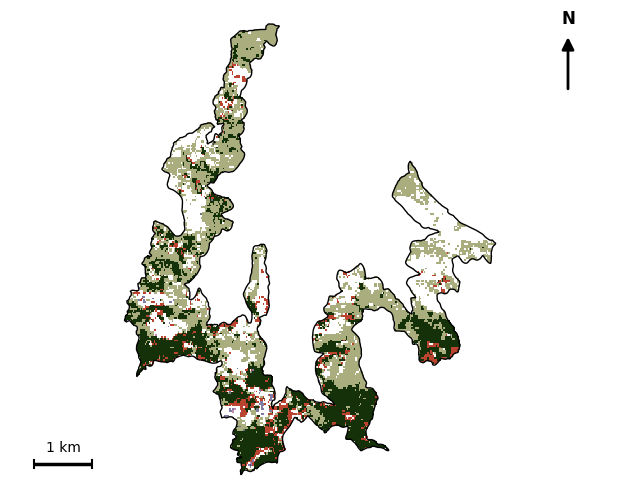

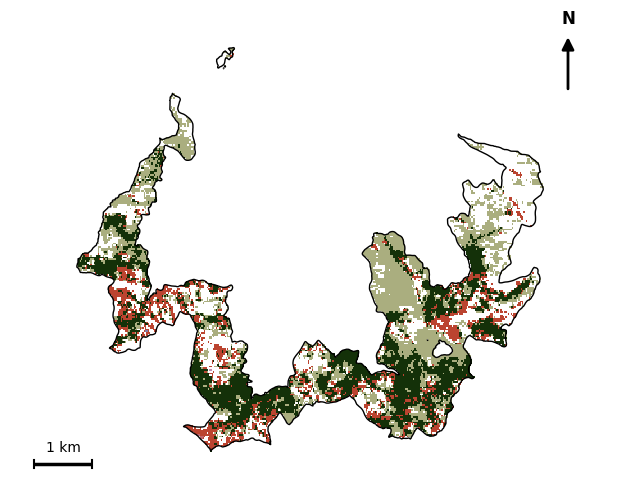

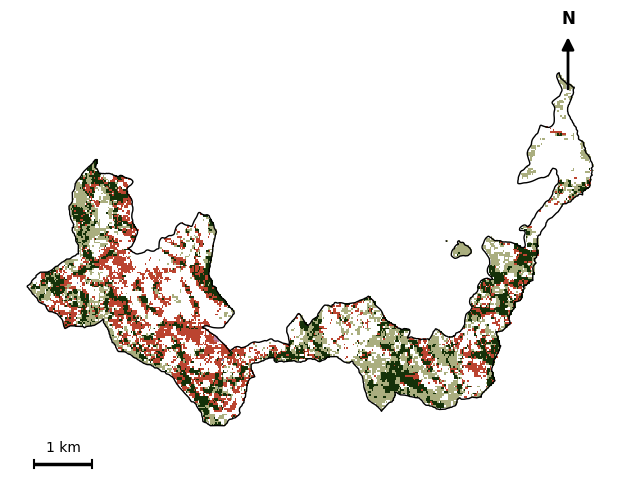

In [8]:
## making maps of each elevation
# parameters
quart_fig_size   = (6, 6)
quart_boundary_color = 'black'
quart_boundary_lw    = 1.0
pad_frac         = 0.03        # margin around the largest quartile (to make all maps the same size/scale)
map_fontsize     = 10          # scale bar / north arrow text size
scalebar_km      = 1
show_legend      = False       # no legend
legend_axes      = [0.66, 0.05, 0.32, 0.32]
legend_fontsize  = 10
os.makedirs(out_dir, exist_ok=True)
tif_path = os.path.join(out_dir, 'bivariate_sig_with_white.tif')

# read values, georeferencing, and crs
with rasterio.open(tif_path) as src:
    arr = src.read(1)
    transform = src.transform
    raster_crs = src.crs

# extent of raster
left, top = transform.c, transform.f
right = left + transform.a * arr.shape[1]
bottom = top + transform.e * arr.shape[0]

cmap = ListedColormap(colors)
plt.rcParams['svg.fonttype'] = 'none'   # keep text editable

# load quartiles and find common window size
gdfs, bounds = {}, {}
for qname, qpath in quartile_files.items():
    g = gpd.read_file(qpath).to_crs(raster_crs) # reproject quartile polygon to raster crs
    gdfs[qname] = g
    bounds[qname] = g.total_bounds   # minx, miny, maxx, maxy

max_w = max(b[2] - b[0] for b in bounds.values()) * (1 + 2 * pad_frac)
max_h = max(b[3] - b[1] for b in bounds.values()) * (1 + 2 * pad_frac)
mid_lat = np.mean([(b[1] + b[3]) / 2 for b in bounds.values()])   # shared by all maps

# draw quartile in same-size window
saved = []
for qname, gdf in gdfs.items():  # clip raster to quartile
    inside = geometry_mask(list(gdf.geometry), out_shape=arr.shape,transform=transform, invert=True)
    arr_q = np.ma.masked_where(~inside | (arr == NODATA), arr)

    # center window on quartile
    bminx, bminy, bmaxx, bmaxy = bounds[qname]
    cx, cy = (bminx + bmaxx) / 2, (bminy + bmaxy) / 2
    minx, maxx = cx - max_w / 2, cx + max_w / 2
    miny, maxy = cy - max_h / 2, cy + max_h / 2

    fig, ax = plt.subplots(figsize=quart_fig_size)
    fig.subplots_adjust(left=0, right=1, bottom=0, top=1)   # same layout for every map

    # adding raster
    ax.imshow(arr_q, cmap=cmap, vmin=0, vmax=8,extent=(left, right, bottom, top),interpolation='nearest', zorder=1)
    gdf.boundary.plot(ax=ax, color=quart_boundary_color,linewidth=quart_boundary_lw, zorder=2) # adding quartile outline

    ax.set_xlim(minx, maxx); ax.set_ylim(miny, maxy)
    ax.set_aspect(1 / np.cos(np.deg2rad(mid_lat)))
    ax.set_axis_off()

    # scale bar
    km_per_deg_lon = 111.32 * np.cos(np.deg2rad(mid_lat))
    bar_deg = scalebar_km / km_per_deg_lon
    x0 = minx + max_w * 0.04
    y0 = miny + max_h * 0.05
    tick_h = max_h * 0.008
    ax.plot([x0, x0 + bar_deg], [y0, y0], color='black', lw=2.5,solid_capstyle='butt', zorder=10)
    for xt in (x0, x0 + bar_deg):
        ax.plot([xt, xt], [y0 - tick_h, y0 + tick_h], color='black', lw=1.5, zorder=10)
    ax.text(x0 + bar_deg / 2, y0 + tick_h * 2.5, f'{scalebar_km} km',ha='center', va='bottom', fontsize=map_fontsize, zorder=10)

    # north arrow
    ax.annotate('', xy=(0.93, 0.95), xytext=(0.93, 0.83), xycoords='axes fraction',arrowprops=dict(arrowstyle='-|>', color='black', lw=2,mutation_scale=18), zorder=10)
    ax.text(0.93, 0.965, 'N', transform=ax.transAxes, ha='center', va='bottom',fontsize=map_fontsize + 2, fontweight='bold', zorder=10)

    # legend (if true)
    if show_legend:
        lax = fig.add_axes(legend_axes)
        draw_legend(lax, fontsize=legend_fontsize, title=False)

    # save svg for each quartile
    svg_path = os.path.join(out_dir, f'bivariate_map_{qname}.svg')
    fig.savefig(svg_path, format='svg', transparent=False)   # no tight bbox -> identical size
    plt.show()
    saved.append(svg_path)

# download all maps
#for p in saved:
 #   files.download(p)